<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_1_series_ventanas.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_1_series_ventanas.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F05_sequences%2Fnotebooks%2Fsesion_05_1_series_ventanas.ipynb)

# SI7011 · Sesión 05 · 1. Una serie de tiempo se convierte en ejemplos
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 1** de las diapositivas. Antes de cualquier red recurrente hay que decidir qué es un ejemplo, cómo se parte una serie sin mirar el futuro y qué número hay que superar. Todo lo que se haga mal aquí da un MAE de validación que la prueba no va a repetir.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | la serie completa y una semana | qué patrones tiene la temperatura |
| 2 | partición en el tiempo y normalización | estadísticos solo del pasado |
| 3 | ventanas de $T = 120$ horas | cuántos ejemplos, y que ninguno cruce un corte |
| 4 | línea base de sentido común | el número que hay que superar |
| 5 | un MLP sobre la ventana aplanada | ¿le gana a la línea base? |
| 6 | barajar antes de partir | una validación demasiado optimista |
| 7 | una CNN 1-D | pesos compartidos a lo largo del tiempo |

**Datos:** Jena Climate (Instituto Max Planck de Biogeoquímica), 14 variables meteorológicas cada 10 minutos entre 2009 y 2016. Corre en CPU en unos 3 minutos. **En Kaggle:** agrega el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) con **Add Input** antes de correr.

In [1]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


## Datos: Jena Climate, una lectura por hora
Cada fila son 14 medidas: presión, temperatura, humedad, viento… Nos quedamos con una lectura por hora, como en el capítulo de series de tiempo de Chollet (*Deep Learning with Python*), pero elegida por su **marca de tiempo** (la del minuto :00) y no tomando una de cada seis filas: el archivo trae algunas marcas de tiempo repetidas y algunos huecos, y contar filas correría la hora sin avisar. Además, el anemómetro marca −9999 cuando falla: una sola de esas lecturas en una ventana, aunque esté normalizada, basta para que un MLP prediga cualquier cosa. La celda los pone en 0 e imprime cuántas repeticiones quitó, cuántos errores de sensor corrigió y cuántos huecos quedan; ninguna ventana cruza un hueco (sección 3). Revisar esto **antes** de entrenar es el contrato de datos de las sesiones 02–04.

### Cargar Jena Climate
La celda busca `jena_climate_2009_2016.csv` en este orden y usa el primero que encuentre. Imprime la **fuente** usada: revísala.

| Plataforma | De dónde salen los datos |
|---|---|
| **Kaggle** | el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) agregado con **Add Input** (`/kaggle/input/...`), sin descargar |
| **Lightning Studio** o **local** | la carpeta `data/` junto al notebook |
| **Colab** | `kagglehub` con el mismo dataset y tu secreto `KAGGLE_API_TOKEN` (el mismo de la sesión 01) |

In [2]:
import os
from pathlib import Path

KAGGLE_HANDLE = 'mnassrib/jena-climate'
ARCHIVO = 'jena_climate_2009_2016.csv'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def buscar_csv():
    for root in ROOTS:
        if root.exists():
            hits = sorted(root.rglob(ARCHIVO))
            if hits:
                return hits[0], str(root)
    if kaggle_token():
        import kagglehub
        path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        return sorted(path.rglob(ARCHIVO))[0], f'kagglehub {KAGGLE_HANDLE}'
    raise FileNotFoundError(f'No encontré {ARCHIVO}: agrégalo con Add Input (Kaggle), ponlo en data/ o configura KAGGLE_API_TOKEN.')

ruta, fuente = buscar_csv()
print('fuente:', fuente, '·', ruta)
with open(ruta) as f:
    COLUMNAS = [c.strip('"') for c in f.readline().strip().split(',')][1:]   # sin 'Date Time'
crudo = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=range(1, 15), dtype=np.float32)
# El anemómetro marca −9999 cuando falla. Una velocidad negativa no existe: se reemplaza por 0 (sin viento).
VIENTO = [COLUMNAS.index('wv (m/s)'), COLUMNAS.index('max. wv (m/s)')]
errores = crudo[:, VIENTO] < 0
crudo[:, VIENTO] = np.where(errores, 0.0, crudo[:, VIENTO])
fechas = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=0, dtype=str)            # 'dd.mm.aaaa hh:mm:ss'
iso = np.array([f'{f[6:10]}-{f[3:5]}-{f[0:2]}T{f[11:19]}' for f in fechas], dtype='datetime64[s]')

# Contrato de datos: una fila por instante y una lectura por hora, elegida por su marca de tiempo (minuto :00),
# no por su posición en el archivo. Así no importa si la copia tiene filas repetidas o le faltan algunas.
_, primera = np.unique(iso, return_index=True)                 # quita marcas de tiempo repetidas (se queda con la primera)
primera = np.sort(primera)
en_punto = (iso[primera].astype('datetime64[m]') - iso[primera].astype('datetime64[h]')) == np.timedelta64(0, 'm')
filas = primera[en_punto]
datos, horas = crudo[filas], iso[filas].astype('datetime64[h]')
temp = datos[:, COLUMNAS.index('T (degC)')]
saltos = np.diff(horas) != np.timedelta64(1, 'h')
print(f'{len(crudo):,} lecturas cada 10 min · {len(iso) - len(primera)} marcas de tiempo repetidas (quitadas) · {int(errores.sum())} lecturas de viento = −9999 (puestas en 0)')
print(f'{len(datos):,} horas · {datos.shape[1]} variables · {int(saltos.sum())} huecos en la serie horaria')

fuente: data · data/jena_climate_2009_2016.csv


420,551 lecturas cada 10 min · 327 marcas de tiempo repetidas (quitadas) · 38 lecturas de viento = −9999 (puestas en 0)
70,037 horas · 14 variables · 4 huecos en la serie horaria


In [3]:
print(', '.join(COLUMNAS))

p (mbar), T (degC), Tpot (K), Tdew (degC), rh (%), VPmax (mbar), VPact (mbar), VPdef (mbar), sh (g/kg), H2OC (mmol/mol), rho (g/m**3), wv (m/s), max. wv (m/s), wd (deg)


## 1. La serie
Ocho años de temperatura y, abajo, una semana. Dos ritmos: el año (verano e invierno) y el día (día y noche).

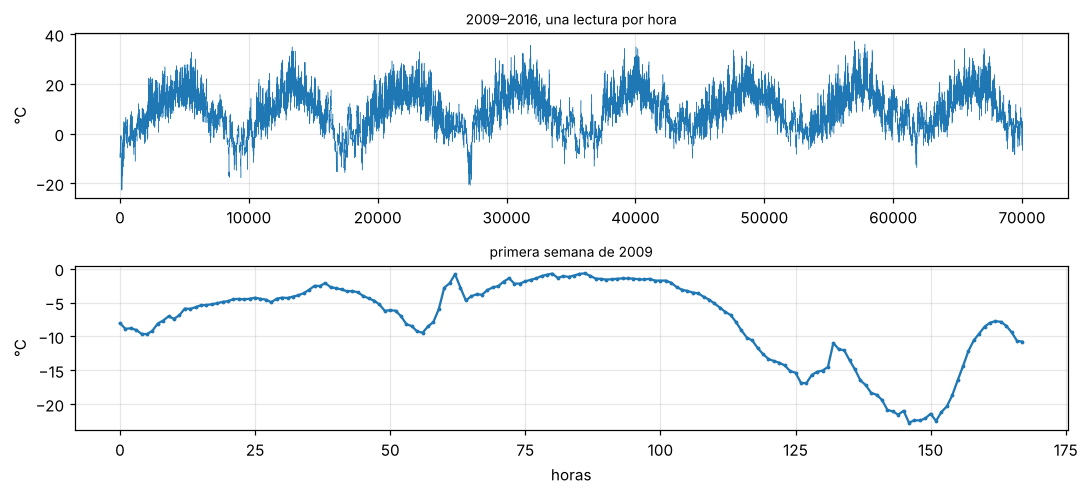

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6))
axes[0].plot(temp, lw=0.3); axes[0].set_ylabel('°C'); axes[0].set_title('2009–2016, una lectura por hora', fontsize=9)
axes[1].plot(temp[:24 * 7], marker='.', ms=3); axes[1].set_ylabel('°C'); axes[1].set_xlabel('horas')
axes[1].set_title('primera semana de 2009', fontsize=9)
plt.tight_layout(); plt.show()

## 2. Partir en el tiempo y normalizar con el pasado
Primero el 50 % para entrenar, luego el 25 % para validar y el último 25 % para la prueba, **en orden**: el modelo se entrena con el pasado y se evalúa con el futuro, como cuando se use.

La media y la desviación con las que se normaliza salen **solo** del bloque de entrenamiento. Si se calcularan con toda la serie, información de los años de prueba entraría en los datos de entrenamiento (fuga 2 de la diapositiva).

In [5]:
N = len(datos)
I_VAL, I_TEST = int(0.5 * N), int(0.75 * N)            # 50 % train · 25 % validación · 25 % prueba, en orden
T, H_FUT = 120, 24                                     # 5 días de entrada → temperatura 24 h después
mu, sd = datos[:I_VAL].mean(0), datos[:I_VAL].std(0)   # estadísticos SOLO del pasado (train)
Xn = (datos - mu) / sd
J_T = COLUMNAS.index('T (degC)')

def inicios(a, b, T=T):
    """Inicios de ventana cuyo objetivo (t + T - 1 + H_FUT) cae dentro del bloque [a, b),
    y que no saltan un hueco de la serie: de la primera hora al objetivo hay exactamente T - 1 + H_FUT horas."""
    ini = np.arange(a, b - T - H_FUT + 1)
    seguidas = (horas[ini + T - 1 + H_FUT] - horas[ini]) == np.timedelta64(T - 1 + H_FUT, 'h')
    return ini[seguidas]

In [6]:
mu_todo = datos.mean(0)
print(f'temperatura media · solo train: {mu[J_T]:.2f} °C · toda la serie: {mu_todo[J_T]:.2f} °C')
print(f'bloques: train {I_VAL:,} h · validación {I_TEST - I_VAL:,} h · prueba {N - I_TEST:,} h')

temperatura media · solo train: 8.82 °C · toda la serie: 9.44 °C
bloques: train 35,018 h · validación 17,509 h · prueba 17,510 h


## 3. Ventanas
Un ejemplo es una ventana de $T = 120$ horas (5 días) de las 14 variables, y su objetivo es la temperatura $H_{\text{fut}} = 24$ horas después del final de la ventana:

$$
\mathbf x_{t-T+1}, \dots, \mathbf x_t \;\longmapsto\; y = \text{temperatura en } t + 24
$$

Cada bloque genera sus propias ventanas, y ninguna puede cruzar un corte: si la ventana está en train y su objetivo en validación, la validación ya no es el futuro (fuga 3).

In [7]:
tr, va, te = inicios(0, I_VAL), inicios(I_VAL, I_TEST), inicios(I_TEST, N)
for nombre, ini, (a, b) in [('train', tr, (0, I_VAL)), ('validación', va, (I_VAL, I_TEST)), ('prueba', te, (I_TEST, N))]:
    assert ini[0] >= a and ini[-1] + T - 1 + H_FUT < b          # ninguna ventana ni objetivo cruza el corte
    print(f'{nombre:11s} {len(ini):6,} ventanas')

train       34,732 ventanas
validación  17,080 ventanas
prueba      17,224 ventanas


In [8]:
# Lo que lee la figura S05-F02 (make_s05_figuras_notebooks.py)
json.dump({'temp': np.round(temp, 1).tolist(), 'cortes': [I_VAL, I_TEST], 'T': T, 'H_fut': H_FUT,
           'ventanas': [int(I_VAL - 3 * (T + H_FUT)), int(I_VAL - 2 * (T + H_FUT)), int(I_VAL - (T + H_FUT))]},
          open('particion_jena.json', 'w'))

## 4. La línea base de sentido común
"La temperatura en 24 horas será la de ahora." No aprende nada y aprovecha el ritmo diario. Un modelo que no la supere no sirve, por complicado que sea.

In [9]:
def mae_base(ini):
    ahora, futuro = temp[ini + T - 1], temp[ini + T - 1 + H_FUT]
    return np.abs(ahora - futuro).mean()

base_val = mae_base(va)
print(f'línea base · MAE validación {base_val:.2f} °C')

línea base · MAE validación 2.44 °C


## Herramientas: ventanas en PyTorch, el loop y el MAE en °C
El modelo predice la temperatura **normalizada**; el MAE se reporta en °C multiplicando por la desviación de train. El loop es el de las sesiones 02–04, con *clipping* del gradiente (Parte 2).

In [10]:
class Ventanas(torch.utils.data.Dataset):
    """x = T horas de las 14 variables normalizadas; y = temperatura normalizada H_FUT horas después."""
    def __init__(self, inicios, T=T):
        self.inicios, self.T = inicios, T
    def __len__(self):
        return len(self.inicios)
    def __getitem__(self, i):
        a = self.inicios[i]
        return torch.from_numpy(Xn[a:a + self.T]), torch.tensor(Xn[a + self.T - 1 + H_FUT, J_T])

def cargador(inicios, T=T, barajar=False):
    return torch.utils.data.DataLoader(Ventanas(inicios, T), batch_size=256, shuffle=barajar)

@torch.no_grad()
def mae(modelo, inicios, T=T):
    """MAE en °C: el modelo predice la temperatura normalizada; se desnormaliza con sd de train."""
    modelo.eval()
    errores = [(modelo(x) - y).abs() for x, y in cargador(inicios, T)]
    return float(torch.cat(errores).mean().item() * sd[J_T])

def entrenar(modelo, inicios_train, inicios_val, T=T, epocas=8, lr=3e-3, recortar=1.0, normas=None):
    opt = torch.optim.Adam(modelo.parameters(), lr)
    t0 = time.time()
    for ep in range(epocas):
        modelo.train()
        for x, y in cargador(inicios_train, T, barajar=True):
            loss = nn.functional.mse_loss(modelo(x), y)
            opt.zero_grad(); loss.backward()
            norma = nn.utils.clip_grad_norm_(modelo.parameters(), recortar)   # devuelve la norma ANTES de recortar
            if normas is not None:
                normas.append(norma.item())
            opt.step()
        print(f'época {ep + 1}: MAE validación {mae(modelo, inicios_val, T):.3f} °C')
    print(f'{time.time() - t0:.0f} s · {sum(p.numel() for p in modelo.parameters()):,} parámetros')
    return modelo

## 5. Un MLP sobre la ventana aplanada
$120 \times 14 = 1680$ entradas, una capa oculta de 16. Antes de correr: ¿le gana a la línea base?

In [11]:
class MLP(nn.Module):
    def __init__(self, T=T, oculta=16):
        super().__init__()
        self.red = nn.Sequential(nn.Flatten(), nn.Linear(T * 14, oculta), nn.ReLU(), nn.Linear(oculta, 1))
    def forward(self, x):                      # x: (B, T, 14), el orden es solo una posición en el vector
        return self.red(x).squeeze(-1)

torch.manual_seed(0)
mlp = entrenar(MLP(), tr, va, epocas=5)
print(f'línea base {base_val:.2f} °C · MLP {mae(mlp, va):.2f} °C')

época 1: MAE validación 2.689 °C


época 2: MAE validación 2.511 °C


época 3: MAE validación 2.520 °C


época 4: MAE validación 2.498 °C


época 5: MAE validación 2.501 °C
2 s · 26,913 parámetros
línea base 2.44 °C · MLP 2.50 °C


El MLP queda **por encima** de la línea base: con 1680 entradas y sin ninguna noción de tiempo, no encuentra siquiera "la temperatura de ahora", que sí está en sus datos. Más parámetros no reemplazan una buena suposición sobre la entrada (sesión 03).

## 6. Una fuga: barajar antes de partir
Ahora partimos **mal**: barajamos todas las ventanas de los primeros 75 % de la serie y separamos al azar 2/3 para entrenar y 1/3 para validar. Ventanas vecinas comparten 119 de sus 120 horas: una cae en train y su gemela en validación.

In [12]:
rng = np.random.default_rng(0)
todas = rng.permutation(inicios(0, I_TEST))
tr_mal, va_mal = todas[:len(todas) * 2 // 3], todas[len(todas) * 2 // 3:]
torch.manual_seed(0)
mlp_mal = entrenar(MLP(), tr_mal, va_mal, epocas=5)
print(f'línea base {base_val:.2f} °C · validación barajada {mae(mlp_mal, va_mal):.2f} °C')
print(f'el mismo modelo en el futuro (el bloque de prueba, que no vio): {mae(mlp_mal, te):.2f} °C')

época 1: MAE validación 2.548 °C


época 2: MAE validación 2.494 °C


época 3: MAE validación 2.373 °C


época 4: MAE validación 2.352 °C


época 5: MAE validación 2.301 °C
2 s · 26,913 parámetros
línea base 2.44 °C · validación barajada 2.30 °C


el mismo modelo en el futuro (el bloque de prueba, que no vio): 2.57 °C


Con la partición barajada la validación sale **mejor que la línea base**, y con ese número uno decidiría que el MLP sirve. Es un espejismo: para cada ventana de validación, el modelo vio en el entrenamiento otra que comparte casi todas sus horas. En el futuro de verdad, el bloque de prueba que no vio nunca, el error sube hasta el nivel de la línea base en ese bloque: el modelo no aprendió nada que la línea base no supiera. La única validación honesta es la temporal de la sección 3. (Aquí miramos la prueba solo para mostrar la fuga; en un experimento real se mira una sola vez, al final.)

## 7. Una CNN 1-D
La convolución de la sesión 03, ahora a lo largo del tiempo: los mismos filtros en cada hora, con un campo receptivo fijo.

In [13]:
class CNN1D(nn.Module):
    def __init__(self, canales=16):
        super().__init__()
        self.red = nn.Sequential(
            nn.Conv1d(14, canales, kernel_size=24), nn.ReLU(), nn.MaxPool1d(2),     # filtros de 24 h
            nn.Conv1d(canales, canales, kernel_size=12), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(canales, canales, kernel_size=6), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(canales, 1))
    def forward(self, x):                      # Conv1d espera (B, canales, T)
        return self.red(x.transpose(1, 2)).squeeze(-1)

torch.manual_seed(0)
cnn = entrenar(CNN1D(), tr, va, epocas=5)
print(f'línea base {base_val:.2f} °C · MLP {mae(mlp, va):.2f} °C · CNN 1-D {mae(cnn, va):.2f} °C')

época 1: MAE validación 3.347 °C


época 2: MAE validación 3.098 °C


época 3: MAE validación 3.138 °C


época 4: MAE validación 3.074 °C


época 5: MAE validación 3.026 °C
10 s · 10,049 parámetros


línea base 2.44 °C · MLP 2.50 °C · CNN 1-D 3.03 °C


Compartir pesos en el tiempo no basta: los filtros miran trozos de horas sin saber **cuándo** ocurrieron dentro de la ventana, y el *pooling* borra el orden. Para predecir la temperatura de mañana importa sobre todo lo que pasó al final de la ventana. Ese es el problema de la Parte 2: un modelo que lea la ventana en orden y resuma lo visto.

## Evaluación en prueba
Una sola vez, al final, con el bloque que nadie tocó.

In [14]:
resultados = {'base': {'val': float(base_val), 'test': float(mae_base(te))},
              'mlp': {'val': mae(mlp, va), 'test': mae(mlp, te)},
              'cnn1d': {'val': mae(cnn, va), 'test': mae(cnn, te)},
              'mlp_barajado': {'val_barajada': mae(mlp_mal, va_mal), 'test': mae(mlp_mal, te)}}
for k in ('base', 'mlp', 'cnn1d'):
    print(f"{k:6s} validación {resultados[k]['val']:.2f} °C · prueba {resultados[k]['test']:.2f} °C")
json.dump(resultados, open('resultados_jena_51.json', 'w'), indent=1)

base   validación 2.44 °C · prueba 2.62 °C
mlp    validación 2.50 °C · prueba 2.67 °C
cnn1d  validación 3.03 °C · prueba 3.22 °C


## Tu turno · 10 minutos
1. Cambia el horizonte a $H_{\text{fut}} = 1$ hora (sección 2) y recalcula la línea base. ¿Qué tan difícil es entonces superarla?
2. En la sección 2, normaliza con `datos.mean(0)` y `datos.std(0)` (toda la serie) y vuelve a entrenar el MLP. ¿Cambia el MAE? ¿Por qué esta fuga es pequeña aquí y no en otros problemas?
3. Dale al MLP solo las últimas 24 horas (`MLP(T=24)` con `cargador(..., T=24)`). ¿Mejora o empeora?

**Para pensar.** La línea base usa una sola de las 1680 entradas. ¿Qué suposición sobre el problema hace, y cómo la incorporarías en una red?

In [15]:
# Tu turno

### Referencias
- Chollet (2021), *Deep Learning with Python*, 2.ª ed., capítulo 10 (Jena Climate, línea base de sentido común).
- Instituto Max Planck de Biogeoquímica, estación meteorológica de Jena, https://www.bgc-jena.mpg.de/wetter/
- Hyndman y Athanasopoulos (2021), *Forecasting: Principles and Practice*, 3.ª ed., capítulo 5 (validación en series de tiempo).